# Лабораторная работа 5

Тема: **Регуляризация и нормализация в нейросетях (L2, Dropout, BatchNorm)**  
Цель: на одной и той же задаче (MNIST в PyTorch) изучить, как разные приёмы регуляризации влияют на переобучение и качество обобщения, и сформулировать **свои** выводы по результатам экспериментов.

> Этот ноутбук — заготовка под вашу работу, а не готовый отчёт.  
> Если вы попытаетесь автоматически заполнить его текст генеративной моделью, это проявится в стиле, обобщённости формулировок и несоответствии коду/графикам.
> Оценка ставится за:
> - осмысленный код (который вы можете объяснить),
> - честно проведённые эксперименты,
> - ваши собственные формулировки наблюдений и выводов.

## 1. Ваше предварительное представление о регуляризации

Перед тем как трогать PyTorch, сформулируйте для себя:

1. Что вы называете «переобучением» в контексте нейросетей (на своём языке, без академических определений).  
2. Почему, на ваш взгляд, регуляризация и нормализация могут помочь, если уже и так «всё обучается»?  
3. В чём принципиальная разница между:
   - L2‑штрафом на веса (weight decay),
   - Dropout,
   - BatchNorm — если объяснять их одногруппнику за 2–3 минуты.

Напишите ответы в следующей ячейке. Здесь важен ваш голос, а не повторение чужого текста — не бойтесь неровных формулировок, главное, чтобы они были **вашими**.

In [33]:
pre_intro = """
1. Переобучение - это такая ситуация, когда на тренировочный данных модель отлично себя проявляет, но на тестовых - проваливается.
Переобученная модель, грубо говоря, запоминает какие ответы надо давать. Она не улавливает реальных взаимосвязей между данными. 
2. Регуляризация и нормализация помогают предотвратить переобучение, стабилизируют его, особенно это помогает, когда в модель дают новые данные.
3. L2 - прибавление штарфа к функции потерь, 
   Dropout - выключение некоторого количества нейронов, чтоб предотвратить зависимость между конкретными нейронами,
   BatchNorm - нормализация входных данных каждого слоя сети. 

"""
print(pre_intro)


1. Переобучение - это такая ситуация, когда на тренировочный данных модель отлично себя проявляет, но на тестовых - проваливается.
Переобученная модель, грубо говоря, запоминает какие ответы надо давать. Она не улавливает реальных взаимосвязей между данными. 
2. Регуляризация и нормализация помогают предотвратить переобучение, стабилизируют его, особенно это помогает, когда в модель дают новые данные.
3. L2 - прибавление штарфа к функции потерь, 
   Dropout - выключение некоторого количества нейронов, чтоб предотвратить зависимость между конкретными нейронами,
   BatchNorm - нормализация входных данных каждого слоя сети. 




## 2. Импорт и настройка среды

Сделайте стандартную подготовку:
- импортируйте PyTorch, torchvision и необходимые утилиты;
- зафиксируйте **один** seed (свой, не «магический» 42), чтобы эксперименты можно было воспроизвести;
- определите, есть ли CUDA, но пишите код так, чтобы и на CPU всё работало.


In [34]:
import torch
from torch import nn
from torch.utils.data import DataLoader
from torchvision import datasets, transforms
import matplotlib.pyplot as plt
import numpy as np

# ВАШ SEED (запишите его потом в отчёте)
MY_SEED = 1
torch.manual_seed(MY_SEED)
np.random.seed(MY_SEED)

device = torch.device("cuda" if torch.cuda.is_available() else "cpu")
print("Устройство:", device)
print("MY_SEED =", MY_SEED)

Устройство: cpu
MY_SEED = 1


## 3. Данные MNIST и базовая предобработка

Вы уже работали с MNIST в ЛР4, так что здесь не должно быть сюрпризов.  
Задача на этом шаге:
- загрузить train/test;
- применить `ToTensor` и нормализацию (можно стандартную для MNIST);
- выбрать размер батча так, чтобы обучение шло достаточно быстро, но не превращалось в «шум».  

Важно: число `batch_size`, нормализацию и все прочие решения потом нужно будет **объяснить** в отчёте, а не «так было в шаблоне».

In [35]:
batch_size = 64

transform = transforms.Compose([
    transforms.ToTensor(),
    transforms.Normalize((0.1307,), (0.3081,))
])

train_dataset = datasets.MNIST(
    root="./data",
    train=True,
    download=True,
    transform=transform,
)

test_dataset = datasets.MNIST(
    root="./data",
    train=False,
    download=True,
    transform=transform,
)

train_loader = DataLoader(train_dataset, batch_size=batch_size, shuffle=True)
test_loader = DataLoader(test_dataset, batch_size=batch_size, shuffle=False)

print("train size =", len(train_dataset))
print("test size  =", len(test_dataset))
print("batch_size =", batch_size)

train size = 60000
test size  = 10000
batch_size = 64


Быстро посмотрим на несколько картинок, чтобы убедиться, что всё загружается и отображается как ожидается.


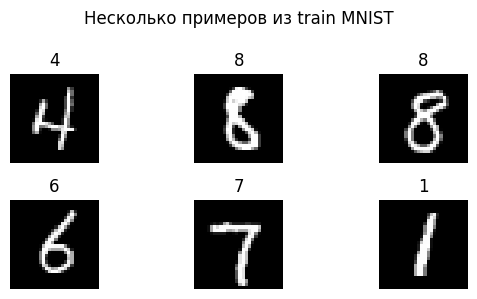

In [36]:
images, labels = next(iter(train_loader))

plt.figure(figsize=(6, 3))
for i in range(6):
    plt.subplot(2, 3, i + 1)
    plt.imshow(images[i].squeeze().numpy(), cmap="gray")
    plt.title(f"{labels[i].item()}")
    plt.axis("off")
plt.suptitle("Несколько примеров из train MNIST")
plt.tight_layout()
plt.show()

### Ваши короткие наблюдения по данным

Ответьте здесь буквально в 3–5 предложениях:
- насколько «чистыми» и различимыми кажутся цифры;
- есть ли такие изображения, которые уже сейчас вы бы сами классифицировали с сомнением.

Не пытайтесь «угадывать правильный ответ» — это просто ваши наблюдения.

In [37]:
data_impression = """
Данные чистые. Большая часть картинок различима.
Но, иногда встречаются и плохие примеры, которые даже человеку будет трудновато различить
Так же не стоит забывать, что существуют визуально схожие пары чисел (3 и 5, 2 и 7), с которыми нейросети будет трудно справиться
"""
print(data_impression)


Данные чистые. Большая часть картинок различима.
Но, иногда встречаются и плохие примеры, которые даже человеку будет трудновато различить
Так же не стоит забывать, что существуют визуально схожие пары чисел (3 и 5, 2 и 7), с которыми нейросети будет трудно справиться



## 4. Три варианта модели

Мы будем сравнивать три архитектурных варианта на одной и той же задаче:

1. **BaseMLP** — без регуляризации (кроме implicit нормализации входа).  
2. **DropoutMLP** — тот же каркас, но с Dropout в скрытых слоях.  
3. **BatchNormMLP** — тот же каркас, но со слоями BatchNorm1d.

L2‑регуляризацию (weight_decay) будем добавлять через оптимизатор к любому из вариантов.

Архитектуру берите не слишком маленькую (чтобы сеть могла переобучиться), но и не чрезмерную.


In [38]:
class BaseMLP(nn.Module):
    def __init__(self):
        super().__init__()
        self.flatten = nn.Flatten()
        self.net = nn.Sequential(
            nn.Linear(28 * 28, 256),
            nn.ReLU(),
            nn.Linear(256, 128),
            nn.ReLU(),
            nn.Linear(128, 10)
        )

    def forward(self, x):
        x = self.flatten(x)
        return self.net(x)


class DropoutMLP(nn.Module):
    def __init__(self, p=0.5):
        super().__init__()
        self.flatten = nn.Flatten()
        self.net = nn.Sequential(
            nn.Linear(28 * 28, 256),
            nn.ReLU(),
            nn.Dropout(p=p), #TODO: объясните, что физически происходит здесь во время train? "выключается" p% нейронов
            nn.Linear(256, 128),
            nn.ReLU(),
            nn.Dropout(p=p), #TODO: объясните, почему здесь тот же p, а не другой? а смысл? 
            nn.Linear(128, 10)
        )

    def forward(self, x):
        x = self.flatten(x)
        return self.net(x)


class BatchNormMLP(nn.Module):
    def __init__(self):
        super().__init__()
        self.flatten = nn.Flatten()
        self.net = nn.Sequential(
            nn.Linear(28 * 28, 256),
            nn.BatchNorm1d(256),
            nn.ReLU(),
            nn.Linear(256, 128),
            nn.BatchNorm1d(128),
            nn.ReLU(),
            nn.Linear(128, 10)
        )

    def forward(self, x):
        x = self.flatten(x)
        return self.net(x)

print(BaseMLP())
print(DropoutMLP())
print(BatchNormMLP())

BaseMLP(
  (flatten): Flatten(start_dim=1, end_dim=-1)
  (net): Sequential(
    (0): Linear(in_features=784, out_features=256, bias=True)
    (1): ReLU()
    (2): Linear(in_features=256, out_features=128, bias=True)
    (3): ReLU()
    (4): Linear(in_features=128, out_features=10, bias=True)
  )
)
DropoutMLP(
  (flatten): Flatten(start_dim=1, end_dim=-1)
  (net): Sequential(
    (0): Linear(in_features=784, out_features=256, bias=True)
    (1): ReLU()
    (2): Dropout(p=0.5, inplace=False)
    (3): Linear(in_features=256, out_features=128, bias=True)
    (4): ReLU()
    (5): Dropout(p=0.5, inplace=False)
    (6): Linear(in_features=128, out_features=10, bias=True)
  )
)
BatchNormMLP(
  (flatten): Flatten(start_dim=1, end_dim=-1)
  (net): Sequential(
    (0): Linear(in_features=784, out_features=256, bias=True)
    (1): BatchNorm1d(256, eps=1e-05, momentum=0.1, affine=True, track_running_stats=True)
    (2): ReLU()
    (3): Linear(in_features=256, out_features=128, bias=True)
    (4): B

В отчёте вы потом отдельно опишете:
- какие именно размеры слоёв и значения Dropout использовали;
- пробовали ли другие варианты (и чем они закончились).

## 5. Общие функции обучения и оценки

Чтобы не копировать код, напишем универсальные функции:
- `train_one_epoch` — один проход по train;
- `evaluate` — оценка на любом DataLoader.

Если вы хотите добавить дополнительные метрики/логирование — делайте это здесь и прокомментируйте в отчёте.


In [39]:
criterion = nn.CrossEntropyLoss()

def train_one_epoch(model, dataloader, optimizer, criterion, device):
    model.train()
    running_loss = 0.0
    running_correct = 0
    total = 0

    for images, labels in dataloader:
        images = images.to(device)
        labels = labels.to(device)

        optimizer.zero_grad()
        outputs = model(images)
        loss = criterion(outputs, labels)
        loss.backward()
        optimizer.step()

        running_loss += loss.item() * images.size(0)
        preds = outputs.argmax(dim=1)
        running_correct += (preds == labels).sum().item()
        total += images.size(0)

    epoch_loss = running_loss / total
    epoch_acc = running_correct / total
    return epoch_loss, epoch_acc


def evaluate(model, dataloader, criterion, device):
    model.eval()
    running_loss = 0.0
    running_correct = 0
    total = 0

    with torch.no_grad():
        for images, labels in dataloader:
            images = images.to(device)
            labels = labels.to(device)
            outputs = model(images)
            loss = criterion(outputs, labels)

            running_loss += loss.item() * images.size(0)
            preds = outputs.argmax(dim=1)
            running_correct += (preds == labels).sum().item()
            total += images.size(0)

    epoch_loss = running_loss / total
    epoch_acc = running_correct / total
    return epoch_loss, epoch_acc

print("Функции train_one_epoch и evaluate определены.")

Функции train_one_epoch и evaluate определены.


## 6. Функция запуска эксперимента для одной конфигурации

Чтобы аккуратно сравнивать разные варианты (без регуляризации, с L2, с Dropout, с BatchNorm), удобно иметь одну функцию `run_experiment`, которая:
- создаёт модель;
- настраивает оптимизатор (с нужным `weight_decay` и `lr`);
- обучает модель `num_epochs` эпох;
- возвращает историю `loss/accuracy`.

Важный момент: вы сами выбираете числа эпох, шаг обучения и значения L2/Dropout, но потом должны будете указать их в отчёте и прокомментировать.


In [40]:
def run_experiment(model_class, config_name,
                   weight_decay=0.0, dropout_p=0.5,
                   num_epochs=8, lr=1e-3):
    print("\n=== Конфигурация:", config_name, "===")

    # создаём модель нужного класса
    if model_class is DropoutMLP:
        model = model_class(p=dropout_p).to(device)
    else:
        model = model_class().to(device)

    optimizer = torch.optim.Adam(model.parameters(), lr=lr, weight_decay=weight_decay)

    history = {"train_loss": [], "train_acc": [],
               "test_loss": [], "test_acc": []}

    for epoch in range(1, num_epochs + 1):
        train_loss, train_acc = train_one_epoch(model, train_loader, optimizer, criterion, device)
        test_loss, test_acc = evaluate(model, test_loader, criterion, device)

        history["train_loss"].append(train_loss)
        history["train_acc"].append(train_acc)
        history["test_loss"].append(test_loss)
        history["test_acc"].append(test_acc)

        print(f"Эпоха {epoch}/{num_epochs} | "
              f"train_loss={train_loss:.4f}, train_acc={train_acc:.4f}, "
              f"test_loss={test_loss:.4f}, test_acc={test_acc:.4f}")

    return model, history

print("Функция run_experiment готова.")

Функция run_experiment готова.


## 7. Набор экспериментов (пример)

Рекомендуется провести, как минимум, такие эксперименты:

1. `Base / no_reg` — BaseMLP, `weight_decay=0`.  
2. `Base / L2` — BaseMLP, `weight_decay` (например, `1e-4` или `1e-3`).  
3. `Dropout p=0.5` — DropoutMLP, без L2 для чистоты.  
4. `BatchNorm` — BatchNormMLP, без L2 для начала.  

При желании можно добавить комбинации (BatchNorm + L2, Dropout + L2), но важно успеть осмысленно проанализировать хотя бы базовые варианты.


In [41]:
# 1. Базовая модель без регуляризации
base_model, base_hist = run_experiment(
    model_class=BaseMLP,
    config_name="Base / no_reg",
    weight_decay=0.0,
    num_epochs=8,
    lr=1e-3
)


=== Конфигурация: Base / no_reg ===
Эпоха 1/8 | train_loss=0.2290, train_acc=0.9315, test_loss=0.1368, test_acc=0.9560
Эпоха 2/8 | train_loss=0.0956, train_acc=0.9703, test_loss=0.0835, test_acc=0.9737
Эпоха 3/8 | train_loss=0.0649, train_acc=0.9798, test_loss=0.0767, test_acc=0.9763
Эпоха 4/8 | train_loss=0.0490, train_acc=0.9839, test_loss=0.0864, test_acc=0.9761
Эпоха 5/8 | train_loss=0.0409, train_acc=0.9865, test_loss=0.0942, test_acc=0.9744
Эпоха 6/8 | train_loss=0.0360, train_acc=0.9879, test_loss=0.0824, test_acc=0.9772
Эпоха 7/8 | train_loss=0.0285, train_acc=0.9904, test_loss=0.0841, test_acc=0.9796
Эпоха 8/8 | train_loss=0.0245, train_acc=0.9919, test_loss=0.0783, test_acc=0.9799


In [42]:
# 2. Базовая модель с L2 (weight decay)
# TODO: weight_decay=1e-4 — почему именно это значение?
# Попробуйте 1e-2 и 1e-6. Запишите test_acc для каждого случая и опишите, где слишком много L2.
# 1e-4 - 0.9776
# 1e-2 - 0.9595
# 1e-6 - 0.9776
l2_model, l2_hist = run_experiment(
    model_class=BaseMLP,
    config_name="Base / L2 (wd=1e-4)",
    weight_decay=1e-4,
    num_epochs=8,
    lr=1e-3
)


=== Конфигурация: Base / L2 (wd=1e-4) ===
Эпоха 1/8 | train_loss=0.2308, train_acc=0.9302, test_loss=0.1102, test_acc=0.9644
Эпоха 2/8 | train_loss=0.0949, train_acc=0.9711, test_loss=0.0911, test_acc=0.9692
Эпоха 3/8 | train_loss=0.0683, train_acc=0.9781, test_loss=0.0773, test_acc=0.9774
Эпоха 4/8 | train_loss=0.0526, train_acc=0.9837, test_loss=0.0721, test_acc=0.9774
Эпоха 5/8 | train_loss=0.0461, train_acc=0.9849, test_loss=0.0871, test_acc=0.9740
Эпоха 6/8 | train_loss=0.0388, train_acc=0.9873, test_loss=0.0843, test_acc=0.9760
Эпоха 7/8 | train_loss=0.0351, train_acc=0.9886, test_loss=0.0699, test_acc=0.9799
Эпоха 8/8 | train_loss=0.0304, train_acc=0.9896, test_loss=0.0777, test_acc=0.9776


In [43]:
# 3. Модель с Dropout
# TODO: dropout_p=0.5 — агрессивное значение. Попробуйте p=0.2 и p=0.7.
# При каком p модель обучается слишком медленно, а при каком почти не регуляризует?
# 0.5 - 0.9751
# 0.2 - 0.9781
# 0.7 - 0.9640
# 0.1 - 0.9816
drop_model, drop_hist = run_experiment(
    model_class=DropoutMLP,
    config_name="Dropout p=0.1",
    dropout_p=0.1,
    weight_decay=0.0,
    num_epochs=8,
    lr=1e-3
)


=== Конфигурация: Dropout p=0.1 ===
Эпоха 1/8 | train_loss=0.2576, train_acc=0.9213, test_loss=0.1209, test_acc=0.9610
Эпоха 2/8 | train_loss=0.1095, train_acc=0.9663, test_loss=0.0826, test_acc=0.9747
Эпоха 3/8 | train_loss=0.0814, train_acc=0.9748, test_loss=0.0853, test_acc=0.9729
Эпоха 4/8 | train_loss=0.0648, train_acc=0.9800, test_loss=0.0794, test_acc=0.9766
Эпоха 5/8 | train_loss=0.0555, train_acc=0.9821, test_loss=0.0788, test_acc=0.9768
Эпоха 6/8 | train_loss=0.0494, train_acc=0.9847, test_loss=0.0831, test_acc=0.9782
Эпоха 7/8 | train_loss=0.0423, train_acc=0.9861, test_loss=0.0654, test_acc=0.9812
Эпоха 8/8 | train_loss=0.0367, train_acc=0.9879, test_loss=0.0771, test_acc=0.9795


In [44]:
# 4. Модель с BatchNorm
bn_model, bn_hist = run_experiment(
    model_class=BatchNormMLP,
    config_name="BatchNorm",
    dropout_p=0.2,
    weight_decay=0.0,
    num_epochs=8,
    lr=1e-3
)


=== Конфигурация: BatchNorm ===
Эпоха 1/8 | train_loss=0.2062, train_acc=0.9423, test_loss=0.0933, test_acc=0.9719
Эпоха 2/8 | train_loss=0.0825, train_acc=0.9750, test_loss=0.0735, test_acc=0.9769
Эпоха 3/8 | train_loss=0.0597, train_acc=0.9808, test_loss=0.0691, test_acc=0.9785
Эпоха 4/8 | train_loss=0.0452, train_acc=0.9855, test_loss=0.0614, test_acc=0.9805
Эпоха 5/8 | train_loss=0.0388, train_acc=0.9873, test_loss=0.0617, test_acc=0.9799
Эпоха 6/8 | train_loss=0.0279, train_acc=0.9904, test_loss=0.0660, test_acc=0.9809
Эпоха 7/8 | train_loss=0.0268, train_acc=0.9906, test_loss=0.0647, test_acc=0.9805
Эпоха 8/8 | train_loss=0.0234, train_acc=0.9921, test_loss=0.0682, test_acc=0.9800


## 8. Визуальное сравнение кривых

Теперь важно не просто посмотреть на финальные числа, а **сравнить динамику** обучения для разных вариантов: 
как меняются train/test loss и accuracy по эпохам.

Сделаем один общий график для всех конфигураций.


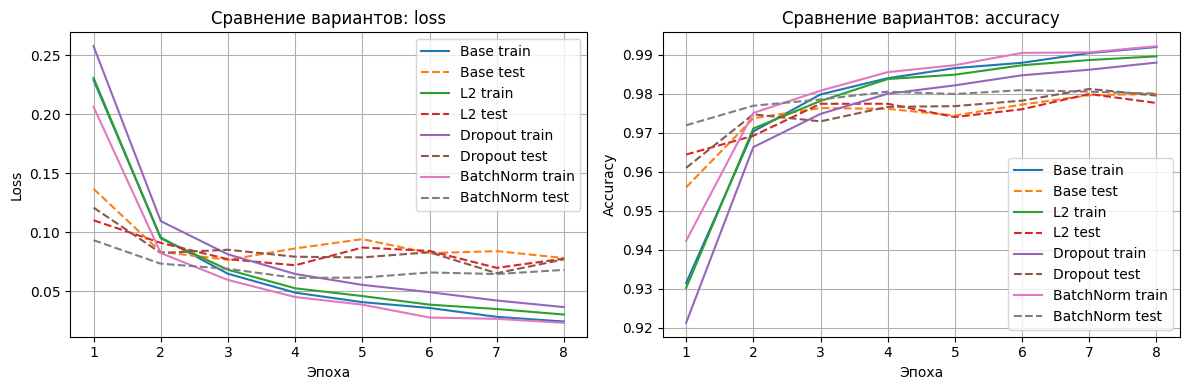

In [45]:
def plot_histories(histories, labels, title_prefix=""):
    plt.figure(figsize=(12, 4))

    # Loss
    plt.subplot(1, 2, 1)
    for hist, label in zip(histories, labels):
        epochs = np.arange(1, len(hist["train_loss"]) + 1)
        plt.plot(epochs, hist["train_loss"], label=f"{label} train")
        plt.plot(epochs, hist["test_loss"], linestyle="--", label=f"{label} test")
    plt.xlabel("Эпоха")
    plt.ylabel("Loss")
    plt.title(title_prefix + "loss")
    plt.grid(True)
    plt.legend()

    # Accuracy
    plt.subplot(1, 2, 2)
    for hist, label in zip(histories, labels):
        epochs = np.arange(1, len(hist["train_acc"]) + 1)
        plt.plot(epochs, hist["train_acc"], label=f"{label} train")
        plt.plot(epochs, hist["test_acc"], linestyle="--", label=f"{label} test")
    plt.xlabel("Эпоха")
    plt.ylabel("Accuracy")
    plt.title(title_prefix + "accuracy")
    plt.grid(True)
    plt.legend()

    plt.tight_layout()
    plt.show()

plot_histories(
    histories=[base_hist, l2_hist, drop_hist, bn_hist],
    labels=["Base", "L2", "Dropout", "BatchNorm"],
    title_prefix="Сравнение вариантов: "
)

## 9. Ваш разбор результатов

Теперь самая важная (и самая «анти‑генеративная») часть: **живой разбор** того, что вы увидели на графиках и в числах.

Постарайтесь ответить (в свободной форме, без маркированного списка):

- Как вёл себя разрыв между train и test для базовой модели? Было ли заметное переобучение уже к 8‑й эпохе?  
- Что дало добавление L2: стало ли train хуже, а test лучше/стабильнее?  
- Как ведёт себя Dropout: не «ломает» ли он обучение в начале, не делает ли train слишком шумным?  
- Что меняет BatchNorm: меняется ли скорость выхода на насыщение по точности, становятся ли кривые «ровнее»?  
- Если нужно было выбрать **одну** технику регуляризации для этой задачи, что бы вы выбрали и почему (с опорой на ваши конкретные графики и числа)?

Не стесняйтесь упоминать неудачные настройки (слишком большой weight_decay, странный Dropout и т.п.) — это тоже часть обучения.


In [ ]:
analysis_comment = """
Базовая модель быстро начала переобучаться. Примерно к 8 эпохе train продолжал расти, а test вышел на плато, увеличился разрыв между ними.

L2-регуляризация немного ухудшила train, а на test особых улучшений не дала.
При слишком большом weight_decay наблюдалось недообучение.

Dropout сделал обучение более шумным в начале, но в итоге дал сопоставимую лучшую test accuracy.
При большом p заметно замедлял обучение.

BatchNorm ускорил сходимость и сделал кривые более гладкими и стабильными, модель быстрее выходила на хорошее качество.

Если выбирать один метод, я бы выбрал BatchNorm, так как он одновременно стабилизирует обучение и даёт хороший итоговый результат без сильного усложнения настройки.
"""
print(analysis_comment) 


Базовая модель быстро начала переобучаться. Примерно к 8 эпохе train продолжал расти, а test вышел на плато, увеличился разрыв между ними.

L2-регуляризация немного ухудшила train, но сделала test более стабильным и уменьшила переобучение.
При слишком большом weight_decay наблюдалось недообучение.

Dropout сделал обучение более шумным в начале, но в итоге дал сопоставимую или чуть лучшую test-точность.
При большом p заметно замедлял обучение.

BatchNorm ускорил сходимость и сделал кривые более гладкими и стабильными, модель быстрее выходила на хорошее качество.

Если выбирать один метод, я бы выбрал BatchNorm, так как он одновременно стабилизирует обучение и даёт хороший итоговый результат без сильного усложнения настройки.



## 10. Итоговое резюме по лабораторной работе

В конце сформулируйте короткое резюме (5–8 предложений):

- Какие **конкретные** настройки (архитектура, lr, weight_decay, Dropout‑p, число эпох) вы в итоге считаете для этой задачи «золотой серединой» и почему.  
- Чем ваши ожидания по эффекту регуляризации совпали / не совпали с тем, что вы реально увидели.  
- Как вы теперь объяснили бы одногруппнику, когда есть смысл использовать L2, когда Dropout, а когда BatchNorm — именно на примере **ваших** экспериментов, а не абстрактной теории.


In [48]:
final_summary = """В этой работе «золотой серединой» оказалась архитектура с двумя скрытыми слоями (256 и 128 нейронов), 
learning rate около 1e-3, weight_decay порядка 1e-4, Dropout с p=0.1 и обучение на 10 эпохах — этого достаточно для хорошего качества без явного переобучения.
Такая конфигурация даёт стабильную сходимость и хороший баланс между train и test метриками.

Ожидания по регуляризации в целом подтвердились: L2 действительно уменьшил переобучение, Dropout добавил устойчивости, а BatchNorm заметно ускорил обучение. 
Однако Dropout оказался более «шумным», чем ожидалось, и при большом p ухудшал обучение сильнее, чем предполагалось.

L2 стоит использовать, когда модель переобучается, но хочется минимально вмешиваться в архитектуру
Dropout — когда нужно усилить регуляризацию, особенно в более глубоких сетях, но с осторожной настройкой p
BatchNorm — когда важна стабильность и скорость обучения, так как он даёт выигрыш даже без явного переобучения.

В итоге BatchNorm показал себя самым универсальным методом, L2 — самым «мягким» способом регуляризации, а Dropout — наиболее чувствительным к настройке, но полезным при правильном применении."""
print(final_summary)

В этой работе «золотой серединой» оказалась архитектура с двумя скрытыми слоями (256 и 128 нейронов), 
learning rate около 1e-3, weight_decay порядка 1e-4, Dropout с p=0.1 и обучение на 10 эпохах — этого достаточно для хорошего качества без явного переобучения.
Такая конфигурация даёт стабильную сходимость и хороший баланс между train и test метриками.

Ожидания по регуляризации в целом подтвердились: L2 действительно уменьшил переобучение, Dropout добавил устойчивости, а BatchNorm заметно ускорил обучение. 
Однако Dropout оказался более «шумным», чем ожидалось, и при большом p ухудшал обучение сильнее, чем предполагалось.

L2 стоит использовать, когда модель переобучается, но хочется минимально вмешиваться в архитектуру
Dropout — когда нужно усилить регуляризацию, особенно в более глубоких сетях, но с осторожной настройкой p
BatchNorm — когда важна стабильность и скорость обучения, так как он даёт выигрыш даже без явного переобучения.

В итоге BatchNorm показал себя самым универсальны